# EDA na Prática - Bloons TD 6
## Quantidade de Bloons por Round

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [5]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "BTD6_Rounds.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "brandonconrady/bloons-tower-defense-6-rounds-1140",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

c:\Users\pedro\AVD-20262-pratica-streamlit\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\pedro\AppData\Local\Temp\ipykernel_37280\697932806.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 14.7k/14.7k [00:00<00:00, 325kB/s]

First 5 records:    Round  RBE  Red  Blue  Green  Camo_Green  Camo_Regen_Green  Yellow  \
0      1   20   20     0      0           0                 0       0   
1      2   35   35     0      0           0                 0       0   
2      3   35   25     5      0           0                 0       0   
3      4   71   35    18      0           0                 0       0   
4      5   59    5    27      0           0                 0       0   

   Regen_Yellow  Camo_Yellow  ...  MOAB  Fortified_MOAB  BFB  Fortified_BFB  \
0             0            0  ...     0               0    0              0   
1             0            0  ...     0               0    0              0   
2             0            0  ...     0               0    0              0   
3             0            0  ...     0               0    0              0   
4             0            0  ...     0               0    0              0   

   ZOMG  Fortified_ZOMG  BAD  Fortified_BAD  DDT  Fortified_DDT  
0  

## 1. Princípio Estrutural

### Dimensão e Tipos de Dados

In [6]:
df.shape

(140, 48)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 48 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Round                         140 non-null    int64
 1   RBE                           140 non-null    int64
 2   Red                           140 non-null    int64
 3   Blue                          140 non-null    int64
 4   Green                         140 non-null    int64
 5   Camo_Green                    140 non-null    int64
 6   Camo_Regen_Green              140 non-null    int64
 7   Yellow                        140 non-null    int64
 8   Regen_Yellow                  140 non-null    int64
 9   Camo_Yellow                   140 non-null    int64
 10  Pink                          140 non-null    int64
 11  Regen_Pink                    140 non-null    int64
 12  Camo_Pink                     140 non-null    int64
 13  Black                         140 n

In [6]:
df.describe()

,Round,RBE,Red,Blue,Green,Camo_Green,Camo_Regen_Green,Yellow,Regen_Yellow,Camo_Yellow,...,MOAB,Fortified_MOAB,BFB,Fortified_BFB,ZOMG,Fortified_ZOMG,BAD,Fortified_BAD,DDT,Fortified_DDT
count,140.0000,1.400000e+02,140.000000,140.00000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,...,140.000000,140.000000,140.000000,140.00000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000
mean,70.5000,1.648658e+05,2.600000,2.80000,4.557143,0.007143,0.142857,2.442857,0.407143,0.092857,...,7.500000,6.114286,3.707143,2.15000,1.307143,0.850000,0.035714,0.007143,2.550000,1.992857
std,40.5586,3.024507e+05,10.921433,11.59397,30.229404,0.084515,1.690309,14.993654,2.676561,1.098701,...,26.866175,20.120889,8.888192,7.96388,4.040971,2.802684,0.279020,0.084515,11.825667,8.797070
min,1.0000,2.000000e+01,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35.7500,6.670000e+02,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,70.5000,9.780000e+03,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,105.2500,1.836425e+05,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,140.0000,1.461456e+06,100.000000,102.00000,343.000000,1.000000,20.000000,160.000000,25.000000,13.000000,...,200.000000,150.000000,42.000000,75.00000,22.000000,18.000000,3.000000,1.000000,99.000000,81.000000


### Duplicadas

In [7]:
df.duplicated().sum()

np.int64(0)

### Criando coluna

In [12]:
df["round_difficulty"] = np.where(df["Round"] > 40, "Hard", "Easy")
print(df["round_difficulty"].value_counts())
df.head()

round_difficulty
Hard    100
Easy     40
Name: count, dtype: int64


,Round,RBE,Red,Blue,Green,Camo_Green,Camo_Regen_Green,Yellow,Regen_Yellow,Camo_Yellow,...,Fortified_MOAB,BFB,Fortified_BFB,ZOMG,Fortified_ZOMG,BAD,Fortified_BAD,DDT,Fortified_DDT,round_difficulty
0,1,20,20,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Easy
1,2,35,35,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Easy
2,3,35,25,5,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Easy
3,4,71,35,18,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Easy
4,5,59,5,27,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Easy


## 2. Dados Faltantes

In [9]:
df.isna().sum()

,0
Round,0
RBE,0
Red,0
Blue,0
Green,0
Camo_Green,0
Camo_Regen_Green,0
Yellow,0
Regen_Yellow,0
Camo_Yellow,0


Sem dados faltantes :)

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [13]:
VARS_QUANT = df.select_dtypes(include=np.number).columns.tolist()

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Round,70.50,70.50,40.56,1.00,140.00,0.00,-1.20
RBE,164865.84,9780.00,302450.74,20.00,1461456.00,2.39,5.73
Red,2.60,0.00,10.92,0.00,100.00,6.30,48.41
Blue,2.80,0.00,11.59,0.00,102.00,6.12,44.02
Green,4.56,0.00,30.23,0.00,343.00,10.39,115.29
Camo_Green,0.01,0.00,0.08,0.00,1.00,11.83,140.00
Camo_Regen_Green,0.14,0.00,1.69,0.00,20.00,11.83,140.00
Yellow,2.44,0.00,14.99,0.00,160.00,8.98,90.07
Regen_Yellow,0.41,0.00,2.68,0.00,25.00,7.47,59.82
Camo_Yellow,0.09,0.00,1.10,0.00,13.00,11.83,140.00


Todas as variáveis, exceto 'Round', parecem ser altamente distorcidas (assimetria bem acima de 1) e têm caudas pesadas (valores de curtose significativamente maiores que 2 em termos absolutos). O próprio 'Round' tem uma assimetria de 0 e uma curtose de -1,2, o que está próximo de uma distribuição normal, mas ainda um pouco mais achatada.

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

Sim,é coerente, pois os valores são esperados em aumentarem de uma forma relativamente "exponencial" pois o data set representa a quantidade de inimigos por rodada no tower defense, então a cada linha aumentam a quantidade de bloons. Por isso a assimetria tão grande para a direita. A única coluna que foge do padrão é Round, o que é esperado ser simétrica pois numera as rodadas do jogo de 1 a 140.

### Distribuições de dados



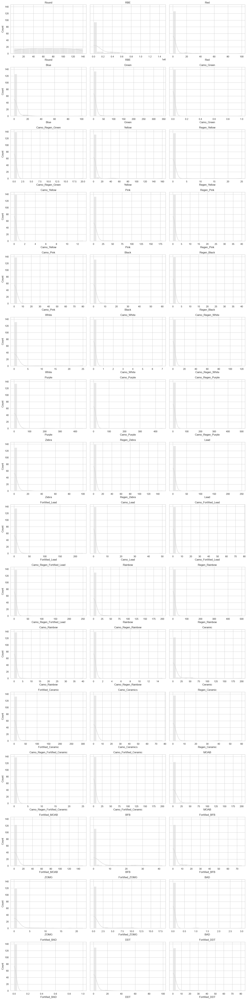

In [14]:
import math

# Calculate the number of rows needed based on the number of variables and desired columns
num_vars = len(VARS_QUANT)
num_cols = 3
num_rows = math.ceil(num_vars / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, 4 * num_rows), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

# Turn off any unused subplots
for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

plt.tight_layout()
plt.show()




In [15]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Easy", COR_CONTEXTO), ("Hard", COR_DESTAQUE)]):
        subset = df[df["round_difficulty"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Round Difficulty (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

Observando os gráficos, várias variáveis mostram um formato de distribuição bem diferente entre as rodadas 'Easy' e 'Hard'.

Por exemplo, as variáveis relacionadas a bloons mais avançados como 'MOAB', 'BFB', 'ZOMG', 'DDT' e suas versões 'Fortified' (ex: 'Fortified_MOAB', 'Fortified_DDT') se destacam. Para as rodadas 'Easy', as contagens desses bloons são predominantemente zero, ou seja, quase não aparecem. Já nas rodadas 'Hard', essas mesmas variáveis mostram distribuições com valores muito maiores e mais dispersos, indicando a presença significativa desses bloons mais fortes.

Até mesmo para alguns bloons básicos, pode haver mudanças sutis na distribuição, como a frequência ou a variação da quantidade que aparece em cada dificuldade. Isso sugere que a dificuldade da rodada é um fator importante que influencia a composição e a quantidade dos bloons em cada rodada.

#### Testes de Aderência


O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `RBE`.

Shapiro-Wilk — RBE: estatística=0.6144, p-valor=1.35e-17
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


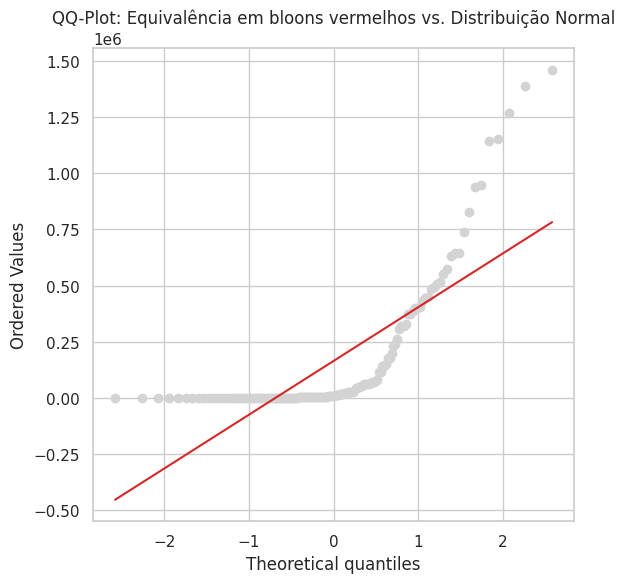

In [13]:
stat_sw, p_valor_sw = stats.shapiro(df["RBE"].dropna())
print(f"Shapiro-Wilk — RBE: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — colesterol"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["RBE"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Equivalência em bloons vermelhos vs. Distribuição Normal")
plt.tight_layout()
plt.show()

In [14]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Round,0.9546,0.000144,True
RBE,0.6144,0.000000,True
Red,0.2578,0.000000,True
Blue,0.2618,0.000000,True
Green,0.1340,0.000000,True
Camo_Green,0.0581,0.000000,True
Camo_Regen_Green,0.0581,0.000000,True
Yellow,0.1539,0.000000,True
Regen_Yellow,0.1415,0.000000,True


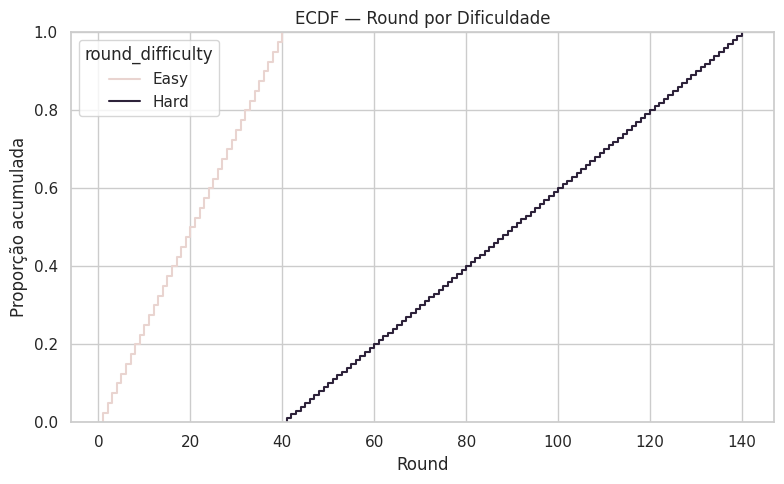

In [15]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Round", hue="round_difficulty",
             palette={"Easy": COR_CONTEXTO, "Hard": COR_DESTAQUE})
plt.title("ECDF — Round por Dificuldade")
plt.xlabel("Round")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

### Métricas de Tendêncial Central

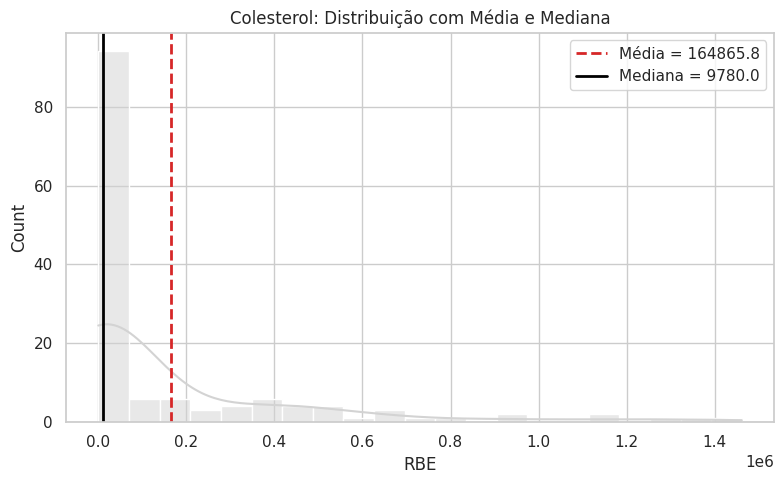

In [16]:
media_RBE = df["RBE"].mean()
mediana_RBE = df["RBE"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="RBE", kde=True, color=COR_NEUTRA)
plt.axvline(media_RBE, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_RBE:.1f}")
plt.axvline(mediana_RBE, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_RBE:.1f}")
plt.title("Colesterol: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão




In [17]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Easy": COR_CONTEXTO, "Hard": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="round_difficulty", y=col, hue="round_difficulty",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="round_difficulty", y=col, hue="round_difficulty",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Dificuldade da Rodada — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

Observando os gráficos de boxplot e violin plot por 'Dificuldade da Rodada' (Easy vs. Hard), é possível notar diferenças marcantes no IQR para várias variáveis. Por exemplo:

RBE (Red Bloon Equivalent): A caixa e o violino para rodadas 'Hard' são muito mais altos e largos do que para rodadas 'Easy', indicando uma quantidade significativamente maior e mais dispersa de RBE em rodadas difíceis.
Tipos de Bloons mais avançados (MOAB, BFB, ZOMG, DDT e suas versões Fortified): Para essas variáveis, as caixas e violinos são praticamente inexistentes ou muito próximos de zero para rodadas 'Easy', enquanto mostram valores e dispersão consideráveis para rodadas 'Hard'. Isso é esperado, pois esses bloons de alto nível aparecem nas rodadas mais avançadas, que foram classificadas como 'Hard'.
Bloons básicos (Red, Blue, Green, etc.): Para alguns desses bloons, as caixas e violinos podem ser mais similares ou até menores em rodadas 'Hard', à medida que eles são substituídos por bloons mais fortes.
Essas diferenças no IQR e na distribuição geral indicam que a variável round_difficulty é um bom indicador para diferenciar os valores de muitas variáveis quantitativas no dataset, o que sugere que ela é relevante para a análise

## 4. Tratamento de Dados Ausentes e Outliers


### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [18]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Round,-68.50,209.50,0.0
RBE,-273796.25,458105.75,18.0
Red,0.00,0.00,13.0
Blue,0.00,0.00,14.0
Green,0.00,0.00,14.0
Camo_Green,0.00,0.00,1.0
Camo_Regen_Green,0.00,0.00,1.0
Yellow,0.00,0.00,11.0
Regen_Yellow,0.00,0.00,4.0
Camo_Yellow,0.00,0.00,1.0


### Visualizando os Outliers




In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

Todos são estatísticos, os dados estão corretamente inseridos e os outliers acontecem apenas por mudanças nas questões de game design do jogo em si.

### Decidindo o Tratamento dos Outliers


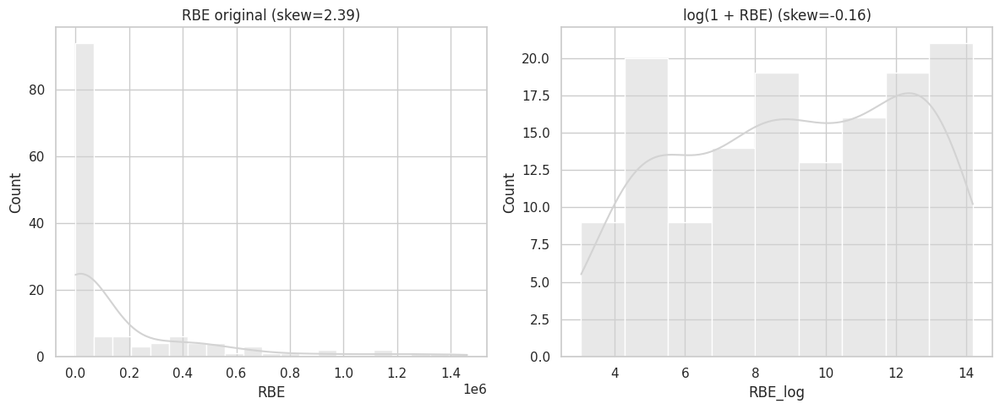

In [ ]:
df["RBE_log"] = np.log1p(df["RBE"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="RBE", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"RBE original (skew={df['RBE'].skew():.2f})")

sns.histplot(data=df, x="RBE_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + RBE) (skew={df['RBE_log'].skew():.2f})")

plt.tight_layout()
plt.show()

A transformação logarítmica reduziu visivelmente a assimetria.

Originalmente, a variável 'RBE' tinha uma assimetria de 2.39. Após a aplicação da transformação log(1 + RBE), a assimetria foi reduzida para -0.16.

Isso é uma redução significativa, movendo a distribuição de uma assimetria positiva forte para algo muito mais próximo de uma distribuição simétrica (onde a assimetria seria zero).

## 5. Estatística Descritiva pt 2

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Round,70.50,70.50,40.56,1.00,140.00,0.00,-1.20
RBE,164865.84,9780.00,302450.74,20.00,1461456.00,2.39,5.73
Red,2.60,0.00,10.92,0.00,100.00,6.30,48.41
Blue,2.80,0.00,11.59,0.00,102.00,6.12,44.02
Green,4.56,0.00,30.23,0.00,343.00,10.39,115.29
Camo_Green,0.01,0.00,0.08,0.00,1.00,11.83,140.00
Camo_Regen_Green,0.14,0.00,1.69,0.00,20.00,11.83,140.00
Yellow,2.44,0.00,14.99,0.00,160.00,8.98,90.07
Regen_Yellow,0.41,0.00,2.68,0.00,25.00,7.47,59.82
Camo_Yellow,0.09,0.00,1.10,0.00,13.00,11.83,140.00


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Round,0.000,0.000,-1.200,-1.200,0.0,0.0
RBE,2.392,2.392,5.732,5.732,0.0,0.0
Red,6.302,6.302,48.407,48.407,0.0,0.0
Blue,6.118,6.118,44.021,44.021,0.0,0.0
Green,10.389,10.389,115.289,115.289,0.0,0.0
Camo_Green,11.832,11.832,140.000,140.000,0.0,0.0
Camo_Regen_Green,11.832,11.832,140.000,140.000,0.0,0.0
Yellow,8.982,8.982,90.071,90.071,0.0,0.0
Regen_Yellow,7.471,7.471,59.818,59.818,0.0,0.0
Camo_Yellow,11.832,11.832,140.000,140.000,0.0,0.0


Então, de fato, menos ainda no meu onde não houve nenhuma diferença pois não tinha nenhum dado ausente.



Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["RBE"].dropna())
print(f"Shapiro-Wilk (antes)  — chol: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — chol: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — chol: estatística=0.6144, p-valor=1.35e-17
Shapiro-Wilk (depois) — chol: estatística=0.6144, p-valor=1.35e-17


**Visualizando antes x depois, lado a lado**

São iguais

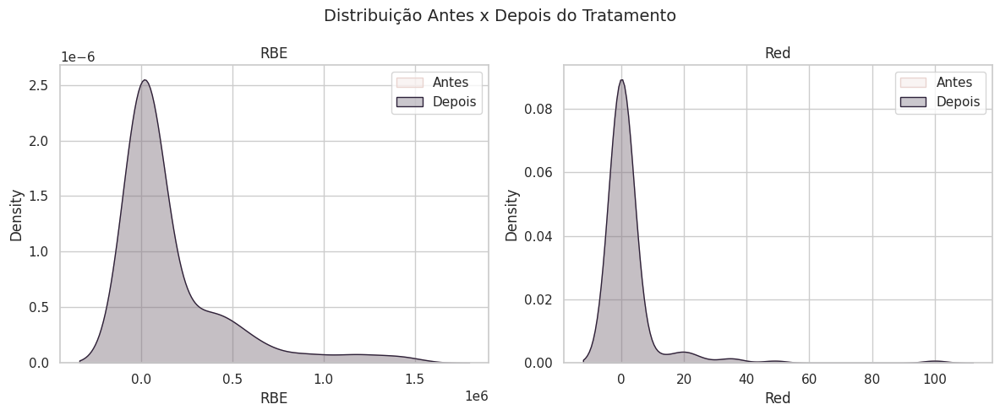

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_antes = df.copy() # Define df_antes to resolve NameError

for ax, col in zip(axes, ["RBE", "Red"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

Como não houve remoção de dados nem alteração dos valores nas colunas quantitativas para estas comparações, as distribuições (e consequentemente as curvas) das variáveis quantitativas permanecem as mesmas. Se tivéssemos removido linhas ou imputado valores, veríamos uma diferença mais clara.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
VARS_QUALI = ['round_difficulty']

for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- round_difficulty ---
                  absoluta  relativa
round_difficulty                    
Hard                   100     0.714
Easy                    40     0.286


#### Visualizando as frequências

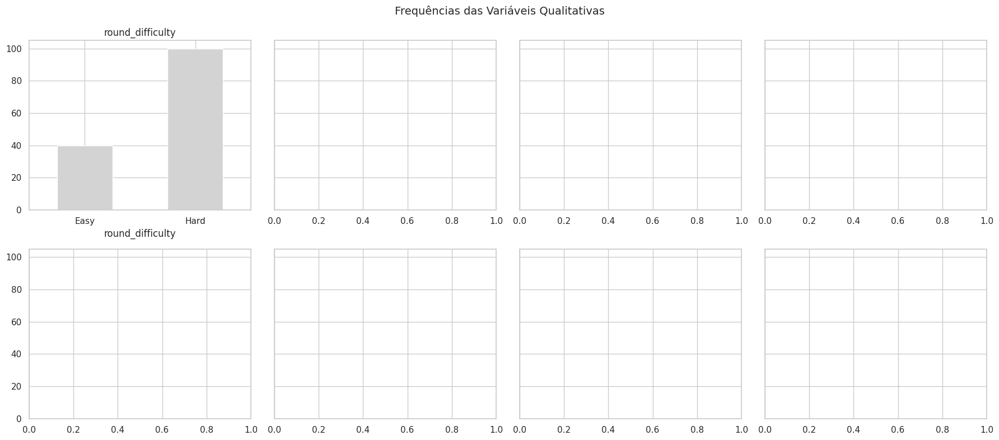

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

Não, meu grafo tem apenas uma variável qualitativa

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["round_difficulty"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
round_difficulty,2.0,2.5,0.863


Nao ha nenhuma variavel com entropia bem proxima de 0

### Análise Bivariada


#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

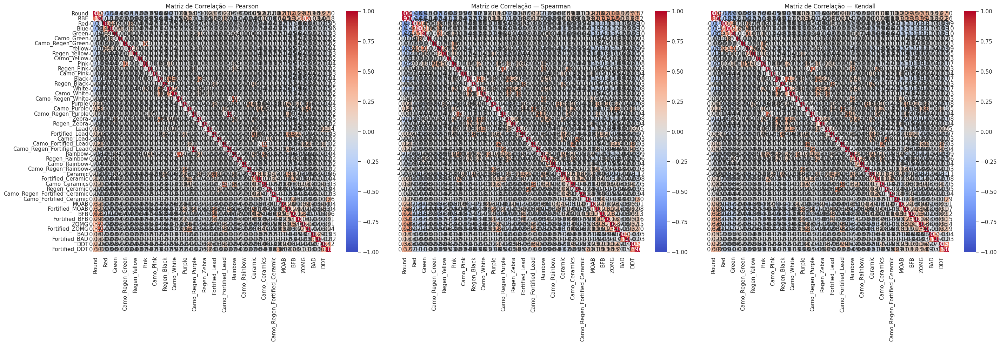

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(29, 10),sharey=True) # Increased figure size
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

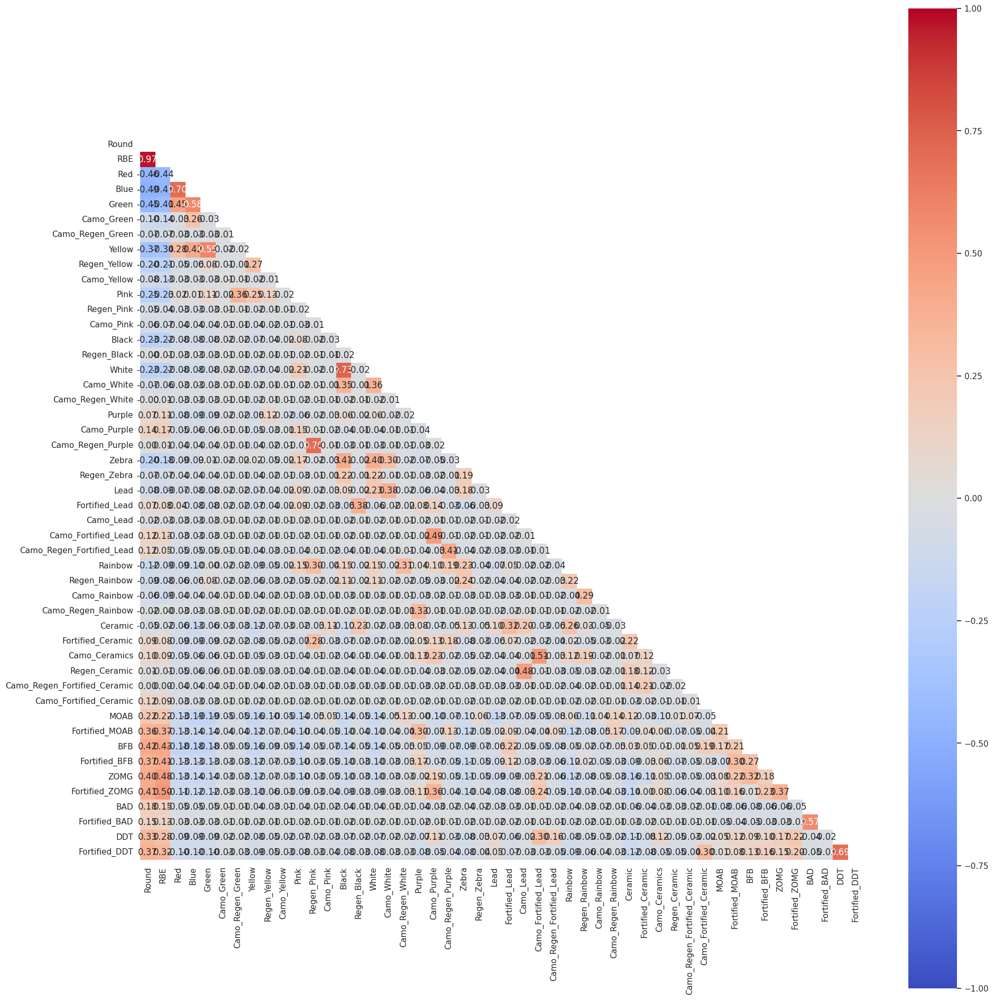

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(20, 20)) # Increased figure size for better readability
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `RBE` x `Red` para ver quantos dos balões vermelhos equivalentes são de fato vermelhos e onde estão presentes.


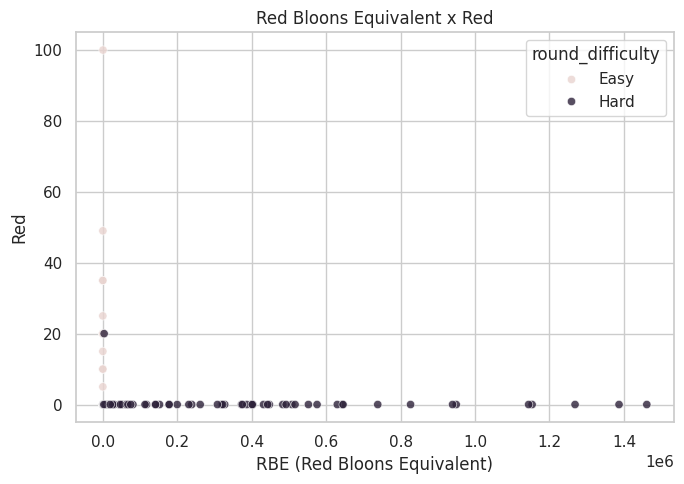

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="RBE", y="Red", hue="round_difficulty",
                palette={"Easy": COR_CONTEXTO, "Hard": COR_DESTAQUE}, alpha=0.8)
plt.title("Red Bloons Equivalent x Red")
plt.xlabel("RBE (Red Bloons Equivalent)")
plt.ylabel("Red")
plt.tight_layout()
plt.show()




Voce percebe que nos rounds mais avancados nao existem mais baloes vermelhos sendo lancados, apenas nos rounds mais faceis.


#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_normal = df.loc[df["round_difficulty"] == "Easy", col]
    grupo_cardiaco = df.loc[df["round_difficulty"] == "Hard", col]

    stat_t, p_t = stats.ttest_ind(grupo_normal, grupo_cardiaco, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_normal, grupo_cardiaco)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")


,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Round,0.00000,0.00000,True
RBE,0.00000,0.00000,True
Red,0.00827,0.00000,True
Blue,0.00393,0.00000,True
Green,0.35731,0.00000,False
Camo_Green,0.32347,0.11751,True
Camo_Regen_Green,0.32347,0.11751,True
Yellow,0.05507,0.00000,False
Regen_Yellow,0.07370,0.00143,False



Analisando a tabela de resultados, podemos observar que os testes concordam na maioria das variáveis (coluna 'concordam' = True), mas existem divergências importantes (False).

Em casos como 'Green', 'Yellow', 'Regen_Yellow', 'Pink', 'Black', 'Purple' e 'Zebra', o teste de Mann-Whitney U encontrou diferenças estatisticamente significativas (p-valor < 0,05) que o Teste-t de Welch não capturou.

ANOVA          — Blue entre Dificuldade: estatística=23.755, p-valor=2.9626e-06
Kruskal-Wallis — Blue entre Dificuldade: estatística=38.474, p-valor=5.5496e-10


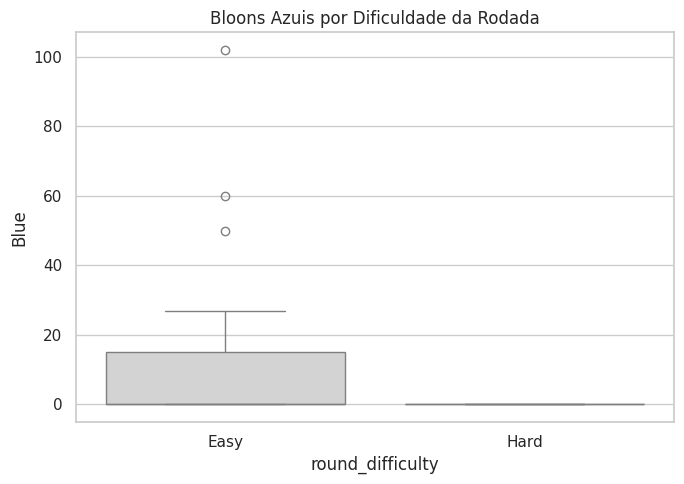

In [ ]:
grupos_diff = [grupo["Blue"].values for _, grupo in df.groupby("round_difficulty")]

# Testes estatísticos comparando Blue bloons entre Easy e Hard
stat_anova, p_anova = stats.f_oneway(*grupos_diff)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_diff)          # não-paramétrico

print(f"ANOVA          — Blue entre Dificuldade: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Blue entre Dificuldade: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="round_difficulty", y="Blue", color=COR_NEUTRA)
plt.title("Bloons Azuis por Dificuldade da Rodada")
plt.tight_layout()
plt.show()

Voce pode observar que bloons azuis sao lancados apenas nos rounds faceis


#### Quantitativa x Qualitativa

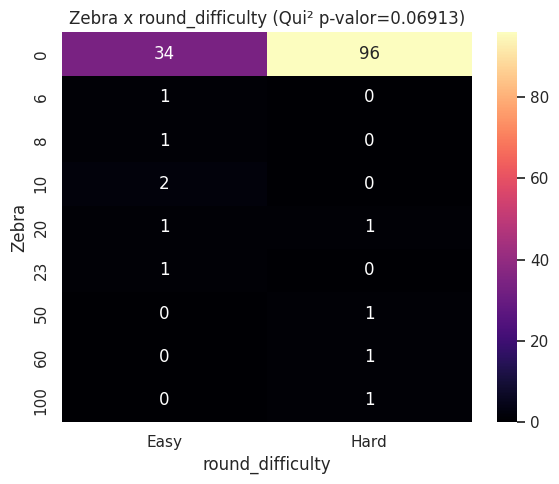

In [ ]:
contingencia_Zebra = pd.crosstab(df["Zebra"], df["round_difficulty"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_Zebra)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_Zebra, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Zebra x round_difficulty (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()




O p-valor obtido foi 0.06913.
Considerando um nível de significância padrão ($α = 0.05$$α = 0.05$):
Como $0.06913 > 0.05$$0.06913 > 0.05$, falhamos em rejeitar a hipótese nula ($H_0$$H_0$).
Isso significa que, sob este limite rigoroso, não há evidência estatística suficiente para afirmar que existe uma associação significativa entre a quantidade de bloons Zebra e a round_difficulty (dificuldade da rodada).
Independência: Estatisticamente, tratamos as variáveis como independentes. No entanto, o valor está relativamente próximo de 0.05 (o que alguns chamam de "tendência à significância"), sugerindo que em um dataset maior ou com critérios diferentes, uma relação poderia ser observada.
Olhando para o heatmap, nota-se que a grande maioria das rodadas (tanto Easy quanto Hard) simplesmente não possui bloons Zebra (o valor 0 domina), o que dilui a força da associação no teste.

Mas esse resultado faz sentido, por decisões de game design o bloon Zebra aparece em determinados rounds pre selecionados

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:


print("Desbalanceamento — Dificuldade da Rodada:")
print(metrica_desbalanceamento(df["round_difficulty"]))

df['rbe_faixa'] = pd.qcut(df['RBE'], q=3, labels=["Baixo RBE", "Médio RBE", "Alto RBE"])

print("\nDesbalanceamento — Faixas de RBE:")
print(metrica_desbalanceamento(df["rbe_faixa"]))

Desbalanceamento — Dificuldade da Rodada:
n_classes                 2.000
razao_desbalanceamento    2.500
entropia_normalizada      0.863
dtype: float64

Desbalanceamento — Faixas de RBE:
n_classes                 3.00
razao_desbalanceamento    1.02
entropia_normalizada      1.00
dtype: float64


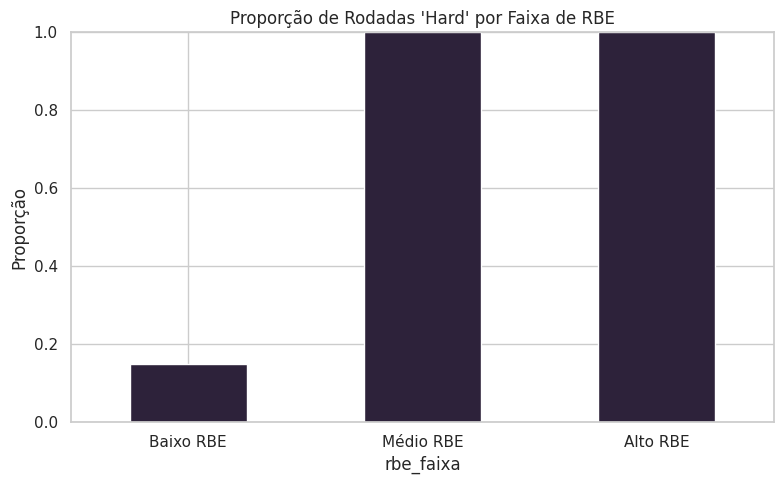

In [ ]:
prop_por_rbe = pd.crosstab(df["rbe_faixa"], df["round_difficulty"], normalize="index").round(3)

fig, ax = plt.subplots(figsize=(8, 5))

# Mostrando a proporção de rodadas 'Hard' para cada faixa de RBE
prop_por_rbe["Hard"].plot(kind="bar", color=COR_DESTAQUE, ax=ax)
ax.set_title("Proporção de Rodadas 'Hard' por Faixa de RBE")
ax.set_ylabel("Proporção")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

você pode ver resultados bem esperados, onde em rounds mais dificeis a equeivalencia em bloons vermelhos dos bloons lancados vai aumentando gradualmente

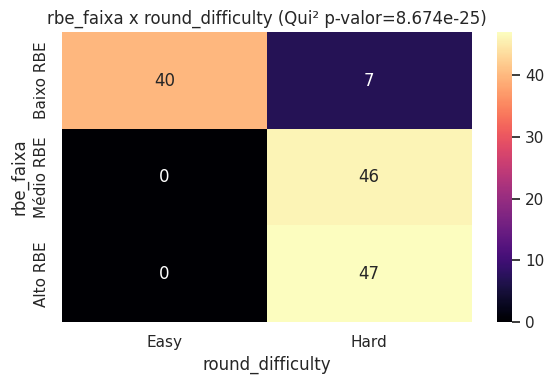

In [ ]:
for atributo in ["rbe_faixa"]:
    contingencia = pd.crosstab(df[atributo], df["round_difficulty"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x round_difficulty (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

Associação Estatística: O teste de Qui-Quadrado retornou um p-valor extremamente baixo (~8.67e-25). Como este valor é muito inferior ao nível de significância padrão ($ \alpha = 0.05 $$ \alpha = 0.05 $), rejeitamos a hipótese nula ($H_0$$H_0$). Isso confirma que existe uma associação estatisticamente significativa entre a faixa de RBE (rbe_faixa) e a dificuldade da rodada (round_difficulty).

Interpretação do Heatmap:

Todas as 40 rodadas Easy estão concentradas na faixa de Baixo RBE.
As rodadas Hard estão distribuídas entre as faixas Média (46) e Alta (47), com apenas 7 rodadas de baixo RBE sendo classificadas como Hard.
Conclusão sobre Fairness: No contexto de Bloons TD 6, essa associação não indica um "viés injusto", mas sim a mecânica central do jogo (Game Design): rodadas mais avançadas (Hard) são deliberadamente projetadas para ter um RBE (densidade de inimigos) maior. Ao contrário de dados sociais ou médicos, onde essa disparidade poderia indicar um problema na coleta ou tratamento, aqui ela valida que a classificação de dificuldade reflete a intensidade real do jogo.

#### Outliers bivariados

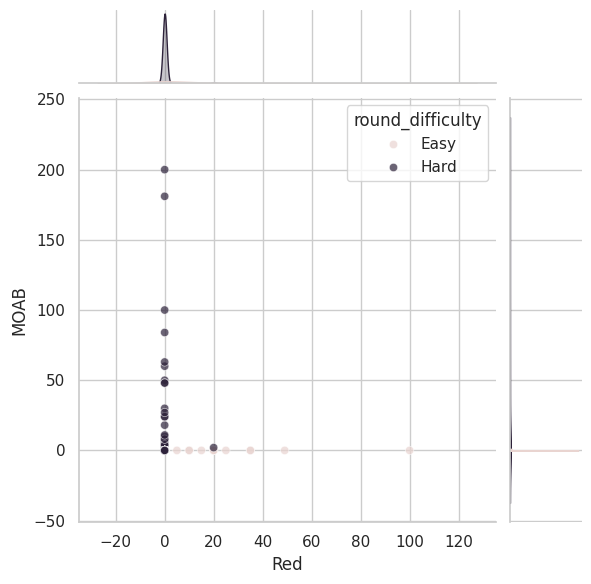

In [ ]:
sns.jointplot(data=df, x="Red", y="MOAB", hue="round_difficulty",
              palette={"Easy": COR_CONTEXTO, "Hard": COR_DESTAQUE}, alpha=0.7, height=6)
plt.show()

#### Análise Multivariada

##### Matriz de Correlação

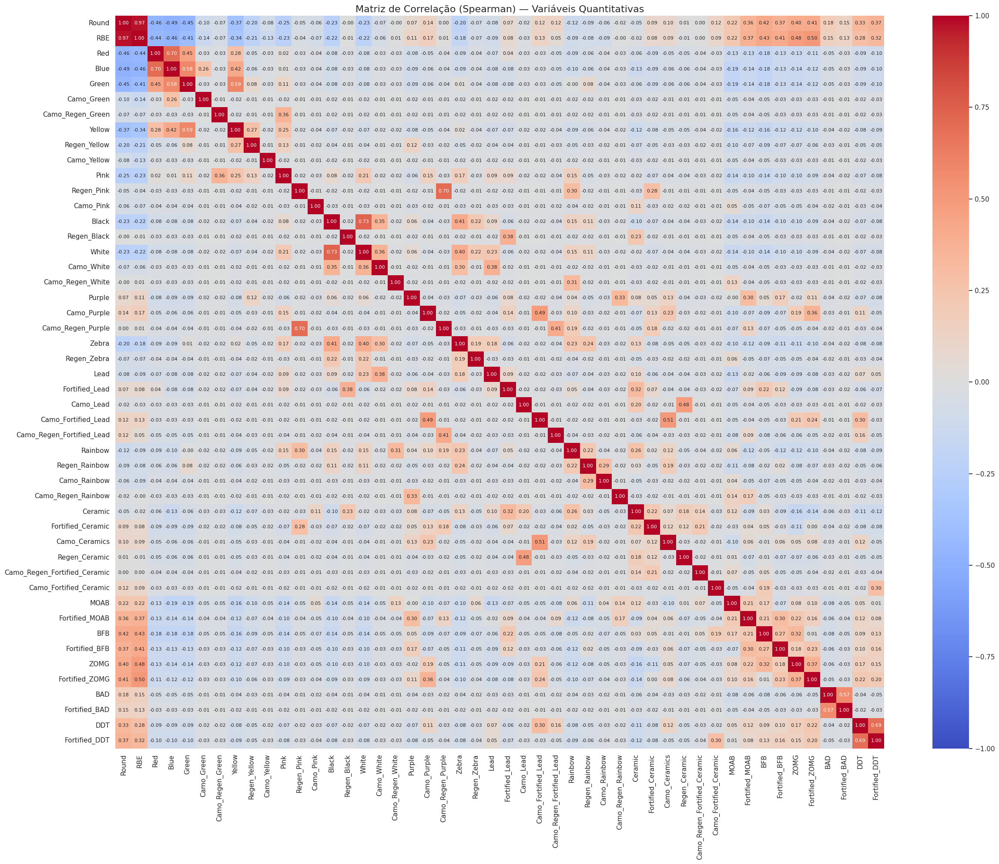

In [ ]:
plt.figure(figsize=(25, 20))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", annot_kws={"size": 8})
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas", fontsize=16)
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Tirando as correlações das colunas entre si que são 1 por motivos óbvios, há alguma correlações justificadas por motivos de game design mesmo. Onde alguns bloons tem mais de 0,7 indicando que eles geralmente aparecem juntos nos rounds. Ex: bloons pretos com bloons brancos vem quase sempre acompanhados


##### Correlograma

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

1.   Principais conclusões em 3 a 5 pontos

* **Dimensões do Dataset**: Contém 140 linhas representando as rodadas do jogo e 48 colunas numéricas iniciais que monitoram a contagem de bloons e o RBE (*Red Bloon Equivalent*) total.
* **Integridade dos Dados**: Apresenta dados completamente limpos, com 0 valores nulos e 0 registros duplicados.
* **Engenharia de Recursos**: Adiciona a classificação `round_difficulty`, dividindo o jogo em 40 rodadas "Fáceis" ($\le 40$) e 100 rodadas "Difíceis" ($> 40$).
* **Análise**: No geral a maioria das conclusões e análises foram para entendimento do dataset e com resultados esperados. A maioria das conclusões vem de decisões de puro game design.



2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

2. Declaração de Uso de Inteligência Artificial (IA)

Ferramenta Utilizada: Google Gemini.

Foi utilizado para alguns pontos:
1. Entendimento de conceitos: Para o esclarecimento de conceitos de estatística que não tinha entendido 100%
2. Análise de análises: Para as matrizes e tabelas muito grande utilzei para identificar os pontos relevantes e outliers.
3. Ajuste de código: Ajuste do código da professora para utilizar variáveis do meu dataset




---
> 🆕 **NOVA SEÇÃO (não estava no notebook da aula)** — as 4 células abaixo (esta, mais 3) servem apenas para salvar os datasets em disco.

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset:

- `data/raw/dataset.csv`: o dataset **original**, como veio da UCI (sem a coluna `doenca_cardiaca`, sem remoção de linhas).
- `data/clean/dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (linhas com `ca`/`thal` ausentes removidas e colunas derivadas criadas). É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.

In [7]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [8]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
df_raw = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "brandonconrady/bloons-tower-defense-6-rounds-1140",
  file_path,
)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

C:\Users\pedro\AppData\Local\Temp\ipykernel_37280\2707187750.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_raw = kagglehub.load_dataset(


Raw salvo em ..\data\raw\dataset.csv — 140 linhas x 48 colunas


In [16]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 140 linhas x 49 colunas
Linhas removidas no tratamento: 0
